# Step 2 — 1D Nonlinear Convection

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step02_nonlinear_convection_1d.ipynb)

*The "12 steps to Navier-Stokes" with sesmax (after Lorena Barba's CFD Python), moved from somax's tutorial series.*

In Step 1 we saw linear convection: a wave translating at constant speed. Now we let the wave speed depend on the solution itself. This seemingly small change introduces dramatic new physics — steepening fronts, shock formation, and the need for upwind schemes.

**What you'll learn:**

1. How nonlinear self-advection steepens wave profiles
2. Why upwind flux reconstruction is essential for stability
3. How to track energy conservation in a nonlinear system
4. How to differentiate through the nonlinear simulation

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

$$
\frac{\partial u}{\partial t} + u \frac{\partial u}{\partial x} = 0
$$

This is the **inviscid Burgers equation** — the simplest nonlinear hyperbolic conservation law. It can be written in conservative form:

$$
\frac{\partial u}{\partial t} + \frac{\partial}{\partial x} \left( \frac{u^2}{2} \right) = 0
$$

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$ is the spatial coordinate (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$ | spatial coordinate | $\mathbb{R}$ |
| $t \in [t_0, t_1]$ | time | $\mathbb{R}$ |
| $u(x, t)$ | the self-advected field, which is also the wave speed | $\mathbb{R}$ |
| $u_0(x)$ | initial condition, a Gaussian bump with centre $\mu_0$ and width $\sigma_0$ | $\mathbb{R}$ |
| $L_x$ | domain length | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x}$ | number of interior grid cells | count |
| $\Delta x = L_x / N_{\Omega_x}$, $\Delta t$ | grid spacing and time step | $\mathbb{R}_{>0}$ |
| $u_n$ | the field in cell $n$; the vector of all cells, with ghosts, has length $N_{\Omega_x} + 2$ | $\mathbb{R}$ |
| $\nu_\text{CFL}$ | Courant number | $\mathbb{R}_{\ge 0}$ |
| $E(t)$ | energy | $\mathbb{R}_{\ge 0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |
| $u^\text{target}(x)$ | target profile of the loss, a Gaussian centred at $x = 2$ | $\mathbb{R}$ |

### Self-steepening

The wave speed is $u$ itself: regions with larger amplitude travel faster. The crest of a positive bump outruns the trough, causing the leading edge to steepen until a **shock** (discontinuity) forms in finite time. After the shock, the classical solution breaks down and one needs weak (entropy) solutions.

In our discrete simulation, the upwind scheme adds enough numerical dissipation to keep the solution stable through mild steepening, but we deliberately stop before a strong shock develops.

## Grid layout and boundary conditions

sesmax uses the **Arakawa C-grid** from finitevolX. In 1D, scalar fields (like $u$) live at **T-points** (cell centres) and fluxes are computed at **U-points** (cell edges). The array holds one ghost cell at each end around the $N_{\Omega_x}$ interior cells:

| Array index | `0` | `1` … `N` | `N + 1` (or `-1`) |
| --- | --- | --- | --- |
| Role | left ghost | interior T-points, where `u` is stored and updated | right ghost |

The U-points sit between neighbouring T-points, a distance $\Delta x$ apart, and that is where the upwind flux reconstruction computes the nonlinear advection term $\partial (u^2 / 2) / \partial x$. The ghost cells are filled by the boundary conditions before each evaluation of the right-hand side.

**Periodic BCs** copy the last interior value into the opposite ghost cell, $u_0 = u_{N_{\Omega_x}}$ and $u_{N_{\Omega_x} + 1} = u_1$, so waves that exit one side re-enter from the other.

In [2]:
import diffrax as dfx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

`NonlinearConvection1D` has no learnable parameters (the wave speed is the solution itself). The model uses upwind flux reconstruction for stability.

In [4]:
# Shapes: N_Ωx = 200 interior cells

num_cells = 200
domain_length = 4.0

# today (sesmax_core)
model = sxt.NonlinearConvection1D.create(nx=num_cells, Lx=domain_length)

print(f"Grid: Nx={model.grid.Nx}, dx={model.grid.dx:.4f}")
print(f"Advection method: {model.method}")

Grid: Nx=202, dx=0.0200
Advection method: upwind1


## 2. Initial condition

A Gaussian bump centred at $\mu_0 = 1.5$ with width $\sigma_0 = 0.3$ and amplitude 1,

$$
u_0(x) = \exp\left(-\frac{(x - \mu_0)^2}{2 \sigma_0^2}\right)
$$

The positive values mean the entire bump travels to the right, but faster at the peak than at the tails.

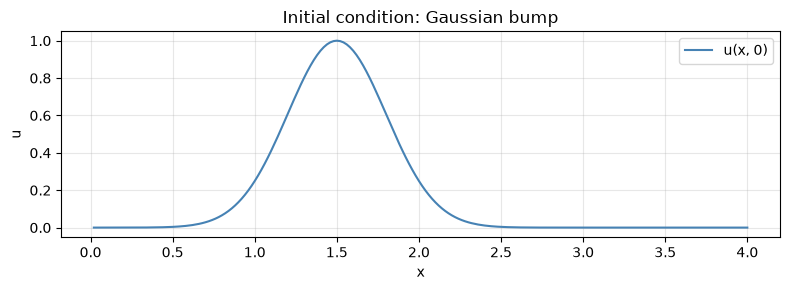

In [5]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

interior = slice(1, -1)
bump_centre = 1.5
bump_width = 0.3

# xₙ = n Δx
position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_Ωx + 2,)
# zₙ = (xₙ − μ₀) / σ₀
standardised = (position - bump_centre) / bump_width  # → (N_Ωx + 2,)
# u₀(x) = exp(−z² / 2)
initial_u = jnp.exp(-0.5 * standardised**2)  # → (N_Ωx + 2,)

# today (sesmax_core)
initial_state = sxt.NonlinearConvection1DState(u=initial_u)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(
    position[interior],
    initial_u[interior],
    color="steelblue",
    lw=1.5,
    label="u(x, 0)",
)
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("Initial condition: Gaussian bump")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Forward simulation — watching the profile steepen

We save snapshots at several times to visualize how the leading edge steepens while the trailing edge stretches.

In [6]:
# Shapes: N_T = 6 saved snapshots; N_Ωx + 2 = 202 cells with the ghosts

start_time = 0.0
end_time = 0.4
time_step = 0.002
save_times = jnp.array([0.0, 0.05, 0.1, 0.2, 0.3, 0.4])  # → (N_T,)

# today (sesmax_core, diffrax)
# u(x, tₖ) for each saved time
solution = model.integrate(  # u → (N_T, N_Ωx + 2)
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

print(f"Trajectory shape: u={solution.ys.u.shape}")

Trajectory shape: u=(6, 202)


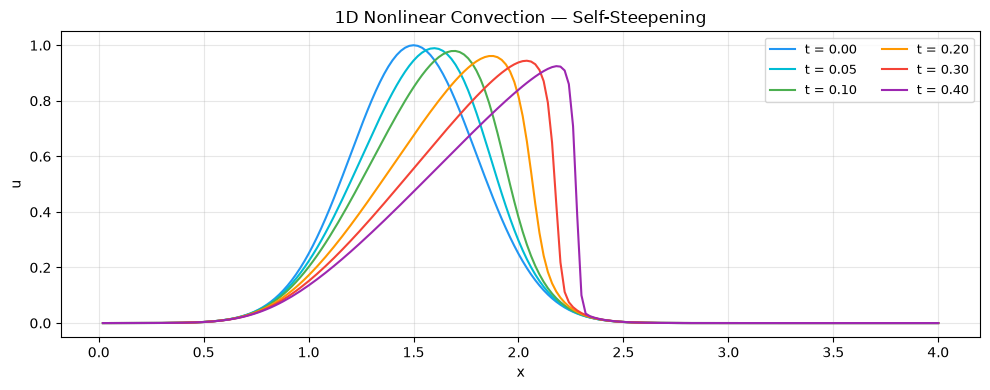

In [7]:
snapshot_colours = ["#2196F3", "#00BCD4", "#4CAF50", "#FF9800", "#F44336", "#9C27B0"]

fig, ax = plt.subplots(figsize=(10, 4))
for snapshot, save_time in enumerate(save_times):
    ax.plot(
        position[interior],
        solution.ys.u[snapshot, interior],
        color=snapshot_colours[snapshot],
        lw=1.5,
        label=f"t = {float(save_time):.2f}",
    )
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("1D Nonlinear Convection — Self-Steepening")
ax.legend(fontsize=9, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Notice how the right edge of the bump steepens: the peak (where $u$ is largest) outruns the base (where $u$ is smaller). This is the hallmark of nonlinear advection.

## 4. Comparing with linear convection

To highlight the nonlinear effect, we overlay the nonlinear result with a pure translation (what linear convection would give for the same initial bump).

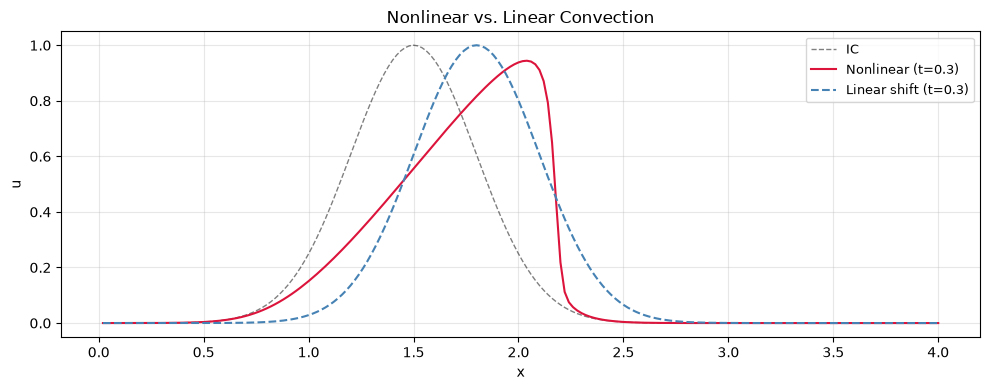

In [8]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

# the snapshot at t = 0.3 is save_times[4]
compare_snapshot = 4
compare_time = 0.3
# the peak was initially at u ≈ 1, so it moves at roughly speed 1
reference_speed = 1.0

# d = c t
travelled = reference_speed * compare_time
# ξ = (x − d) mod L_x
shifted_position = (position - travelled) % domain_length  # → (N_Ωx + 2,)
# zₙ = (ξₙ − μ₀) / σ₀
shifted_standardised = (shifted_position - bump_centre) / bump_width  # → (N_Ωx + 2,)
# u(x) = exp(−z² / 2)
linear_u = jnp.exp(-0.5 * shifted_standardised**2)  # → (N_Ωx + 2,)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(position[interior], initial_u[interior], "k--", lw=1.0, alpha=0.5, label="IC")
ax.plot(
    position[interior],
    solution.ys.u[compare_snapshot, interior],
    color="crimson",
    lw=1.5,
    label=f"Nonlinear (t={compare_time})",
)
ax.plot(
    position[interior],
    linear_u[interior],
    color="steelblue",
    lw=1.5,
    ls="--",
    label=f"Linear shift (t={compare_time})",
)
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("Nonlinear vs. Linear Convection")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Energy evolution

For the inviscid Burgers equation, the $L^2$ energy is conserved analytically (before shock formation),

$$
E(t) = \frac{1}{2} \int_0^{L_x} u(x, t)^2 \mathrm{d}x
$$

Numerically, the upwind scheme introduces dissipation — this is actually desirable as it provides the entropy condition needed to select the physically correct weak solution.

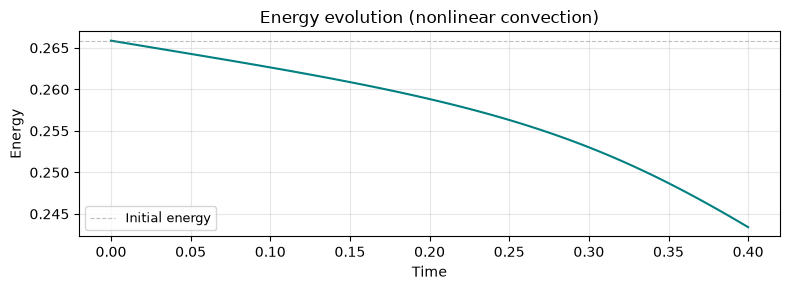

Energy: initial = 0.265868, final = 0.243400
Relative change: 8.4509%


In [9]:
# Shapes: N_T = 100 saved snapshots; N_Ωx + 2 = 202 cells with the ghosts

# tₖ, k = 0, …, N_T − 1
dense_times = jnp.linspace(start_time, end_time, 100)  # → (N_T,)

# today (sesmax_core, diffrax)
dense_solution = model.integrate(  # u → (N_T, N_Ωx + 2)
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=dense_times),
)

# today (sesmax_core)
# E(tₖ) = (Δx / 2) Σₙ uₙ(tₖ)²
diagnostics = jax.vmap(model.diagnose)(dense_solution.ys)
energy = diagnostics.energy  # → (N_T,)
# |E(t₁) − E(t₀)| / E(t₀)
relative_change = jnp.abs(energy[-1] - energy[0]) / energy[0]  # → ()

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(dense_times, energy, color="teal", lw=1.5)
ax.axhline(
    float(energy[0]), color="gray", ls="--", lw=0.8, alpha=0.5, label="Initial energy"
)
ax.set_xlabel("Time")
ax.set_ylabel("Energy")
ax.set_title("Energy evolution (nonlinear convection)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Energy: initial = {float(energy[0]):.6f}, final = {float(energy[-1]):.6f}")
print(f"Relative change: {float(relative_change):.4%}")

## 6. A note on upwind schemes and stability

The nonlinear convection equation requires careful numerical treatment:

- **Upwind schemes** bias the stencil in the direction from which information propagates. sesmax uses `"upwind1"` (first-order upwind) by default, which is diffusive but unconditionally entropy-stable.
- **Central differences** (what you might try first) are unstable for hyperbolic equations — they produce unphysical oscillations.
- **Higher-order methods** (WENO, PPM) reduce numerical diffusion while maintaining stability near shocks.

The CFL condition for Burgers' equation uses the maximum wave speed, $\Delta t \le \Delta x / \max_n \vert u_n \vert$.

In [10]:
# Shapes: N_Ωx + 2 = 202 cells with the ghosts

# maxₙ |u₀,ₙ|
max_speed = jnp.max(jnp.abs(initial_u))  # → ()
# ν_CFL = maxₙ |uₙ| Δt / Δx
courant_number = max_speed * time_step / model.grid.dx  # → ()

print(f"CFL number (initial): max|u| * dt / dx = {courant_number:.3f}")

CFL number (initial): max|u| * dt / dx = 0.100


## 7. Differentiability demo

Even though the model has no explicit learnable parameters, we can still differentiate with respect to the **initial condition**. This is useful for data assimilation and optimal control. The loss compares the field at $t_1 = 0.2$ with a target Gaussian centred at $x = 2$,

$$
\mathcal{L}(u_0) = \frac{1}{N_{\Omega_x}} \sum_{n=1}^{N_{\Omega_x}} \left(u_n(t_1; u_0) - u_n^\text{target}\right)^2
$$

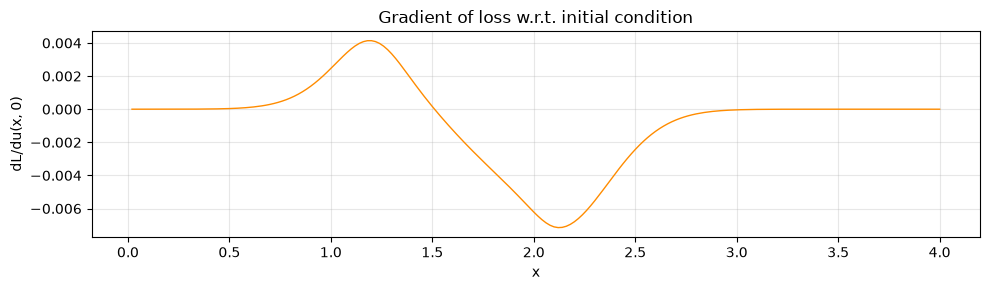

Max |dL/du0|: 0.007150


In [11]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

target_centre = 2.0

# zₙ = (xₙ − 2.0) / σ₀
target_standardised = (position - target_centre) / bump_width  # → (N_Ωx + 2,)
# uᵗᵃʳᵍᵉᵗ(x) = exp(−z² / 2)
target_u = jnp.exp(-0.5 * target_standardised**2)  # → (N_Ωx + 2,)


def loss_of_state(state):
    """MSE ℒ(u₀) between the final profile and a target shifted Gaussian."""
    # today (sesmax_core, diffrax)
    # u(x, t₁; u₀)
    final_solution = model.integrate(state, t0=0.0, t1=0.2, dt=0.002)
    predicted_u = final_solution.ys.u[-1]  # → (N_Ωx + 2,)
    # rₙ = uₙ(t₁; u₀) − uₙᵗᵃʳᵍᵉᵗ
    residual = predicted_u[interior] - target_u[interior]  # → (N_Ωx,)
    # ℒ(u₀) = (1/N_Ωx) Σₙ rₙ²
    loss = jnp.mean(residual**2)  # → ()
    return loss


# ∂ℒ/∂u₀
state_grads = jax.grad(loss_of_state)(initial_state)  # u → (N_Ωx + 2,)
interior_grad = state_grads.u[interior]  # → (N_Ωx,)
# maxₙ |∂ℒ/∂u₀,ₙ|
max_grad = jnp.max(jnp.abs(interior_grad))  # → ()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(position[interior], interior_grad, color="darkorange", lw=1.0)
ax.set_xlabel("x")
ax.set_ylabel("dL/du(x, 0)")
ax.set_title("Gradient of loss w.r.t. initial condition")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Max |dL/du0|: {float(max_grad):.6f}")

## Summary

| Concept | sesmax API |
|---------|-----------|
| Create model | `NonlinearConvection1D.create(nx=200, Lx=4.0)` |
| Initial state | `NonlinearConvection1DState(u=...)` |
| Forward sim | `model.integrate(state0, t0, t1, dt, saveat=...)` |
| Energy check | `model.diagnose(state).energy` |
| Grad w.r.t. IC | `jax.grad(loss)(state0)` |

**Key takeaway:** Nonlinear convection causes self-steepening — the wave speed depends on amplitude. Upwind schemes provide the numerical dissipation needed for stability.

**Next:** [Step 3 — Diffusion](step03_diffusion_1d.ipynb) introduces viscosity, which smooths gradients and dissipates energy.